# moonshot_ml_sandbox — V1 linear regression

**Goal.** Fit the simplest possible predictor — a weighted sum of the five
z-scored features — against the forward-return target, and learn to read what it
tells us. This is the foundation everything else (including neural nets) sits on.

**The model, in one line:**  `y_hat = w . f + b`  — take each stock-day's five
features `f`, multiply by learned weights `w`, add them up, add an intercept `b`.
Geometrically: **a direction through the 5-D feature cloud**, and the prediction
is how far along that direction a stock sits. Fitting = finding the direction
that best sorts stocks by their forward return.

**What we do:**
1. **Rolling folds** — train 3 years, test the next 1, roll forward. ~12 folds.
   A *purge gap* prevents the train/test boundary from leaking.
2. **Exact solve** (normal equation) on every fold — the ground-truth weights.
3. **Gradient descent from scratch** on one fold — the iterative method neural
   nets use — and confirm it converges to the exact answer.
4. **Score honestly** on each test fold: R2, Pearson IC, rank IC.
5. **Six charts** to see how the fit works and what the features tell us.

**What we expect (set honestly up front):**
- **R2 will be low** — low single-digit percent, maybe near-zero or negative on
  some folds. That is NOT failure. The features are cross-sectional (market-
  neutral); the V1 target is *absolute* return (mostly market direction the
  features can't see). A *high* R2 would be a red flag for leakage, not a win.
- **The real scorecard is IC** — the daily rank correlation between predicted and
  actual returns. A small (0.02-0.05) but *consistently positive* IC is real
  signal in cross-sectional equity. We read mean IC, how often it's positive,
  and how it moves over time.

**This is a learning exercise, not a strategy test.** ~12 folds are not multiple-
testing-corrected; a positive average IC is encouraging, not a validated edge.

**Purge-gap decision (pragmatic, documented):** we fully purge the *target* side
(drop late-training cards whose 21-day target reaches past the train cutoff — a
true label leak). We *document* a mild feature-side overlap: early-test cards'
features look back up to a year into training-period *prices*. That shares input
history but never shares the *answer* (past prices, not past targets), so it is a
known mild impurity, not a label leak. Fully purging it would gut the test set.

## Cell 0 — Mount + load V1 dataset (read-only)

In [2]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')

SANDBOX_DIR = Path("/content/drive/MyDrive/moonshot_ml_sandbox")
datasets = sorted(SANDBOX_DIR.glob("ml_sandbox_v1_dataset_*.parquet"))
assert datasets, f"No V1 dataset in {SANDBOX_DIR} (build it first)."
DATASET_PATH = datasets[-1]
print(f"Loading (READ-ONLY): {DATASET_PATH.name}")

Mounted at /content/drive
Loading (READ-ONLY): ml_sandbox_v1_dataset_2026-09-07.parquet


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet(DATASET_PATH)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["date", "ticker"]).reset_index(drop=True)

RAW = ["momentum_12_1", "reversal_1m", "realized_vol_60", "log_turnover", "overnight_drift"]
Z   = [f + "_z" for f in RAW]
TARGET = "fwd_ret_20d"
NICE = {"momentum_12_1":"Momentum","reversal_1m":"Reversal","realized_vol_60":"Realized vol",
        "log_turnover":"Log-turnover","overnight_drift":"Overnight drift"}

# figure export (save each figure as it's made — plt.show() clears it otherwise)
EXPORT_DIR = SANDBOX_DIR / "viz_exports_regression"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
_fig = {"n": 0}
def save_fig(fig, name):
    _fig["n"] += 1
    p = EXPORT_DIR / f"{_fig['n']:02d}_{name}.png"
    fig.savefig(p, dpi=130, bbox_inches="tight"); print(f"  [saved: {p.name}]")

print(f"{len(df):,} cards | {df['ticker'].nunique():,} tickers | "
      f"{df['date'].min().date()} -> {df['date'].max().date()}")
print(f"figures -> {EXPORT_DIR}")

1,813,407 cards | 1,041 tickers | 2011-01-03 -> 2026-06-10
figures -> /content/drive/MyDrive/moonshot_ml_sandbox/viz_exports_regression


## Cell 1 — Define rolling folds + the purge gap (shown explicitly)

Train on 3 calendar years, test on the next. Roll forward one year and repeat.

**The purge gap, made visible.** The target is `open[t+1] -> open[t+21]`, so a
training card's target reaches ~21 trading days past its own date. Any training
card whose target extends *past the train cutoff* (Dec 31 of the last train year)
is dropped — its label peeks into the test period. We print the train / purge /
test date ranges and the dropped-card count for every fold so the gap is not an
article of faith.

In [4]:
# Trading calendar = the sorted unique dates actually in the panel.
all_dates = np.array(sorted(df["date"].unique()))

# Build folds: train [y0..y0+2], test [y0+3], for y0 = 2011..2022
folds = []
for y0 in range(2011, 2023):
    train_lo = pd.Timestamp(f"{y0}-01-01")
    train_hi = pd.Timestamp(f"{y0+2}-12-31")
    test_lo  = pd.Timestamp(f"{y0+3}-01-01")
    test_hi  = pd.Timestamp(f"{y0+3}-12-31")
    if test_lo > df["date"].max():
        break
    # target-side purge: drop train cards within ~21 trading days of train_hi,
    # since their 21-day-forward target would cross into the test period.
    hi_pos = np.searchsorted(all_dates, np.datetime64(train_hi), side="right") - 1
    last_safe_pos = hi_pos - 21
    purge_from = (pd.Timestamp(all_dates[last_safe_pos + 1])
                  if 0 <= last_safe_pos + 1 < len(all_dates) else train_hi)
    folds.append(dict(y0=y0, train_lo=train_lo, train_hi=train_hi,
                      test_lo=test_lo, test_hi=test_hi, purge_from=purge_from))

print(f"{len(folds)} folds defined.\n")
print(f"{'fold':<6}{'train (kept)':<26}{'PURGE (dropped)':<26}{'test':<20}")
for f in folds:
    tr = f"{f['train_lo'].date()}..{f['purge_from'].date()}"
    pg = f"{f['purge_from'].date()}..{f['train_hi'].date()}"
    te = f"{f['test_lo'].date()}..{f['test_hi'].date()}"
    print(f"{f['y0']-2011:<6}{tr:<26}{pg:<26}{te:<20}")

12 folds defined.

fold  train (kept)              PURGE (dropped)           test                
0     2011-01-01..2013-12-02    2013-12-02..2013-12-31    2014-01-01..2014-12-31
1     2012-01-01..2014-12-02    2014-12-02..2014-12-31    2015-01-01..2015-12-31
2     2013-01-01..2015-12-02    2015-12-02..2015-12-31    2016-01-01..2016-12-31
3     2014-01-01..2016-12-02    2016-12-02..2016-12-31    2017-01-01..2017-12-31
4     2015-01-01..2017-11-30    2017-11-30..2017-12-31    2018-01-01..2018-12-31
5     2016-01-01..2018-11-30    2018-11-30..2018-12-31    2019-01-01..2019-12-31
6     2017-01-01..2019-12-02    2019-12-02..2019-12-31    2020-01-01..2020-12-31
7     2018-01-01..2020-12-02    2020-12-02..2020-12-31    2021-01-01..2021-12-31
8     2019-01-01..2021-12-03    2021-12-03..2021-12-31    2022-01-01..2022-12-31
9     2020-01-01..2022-12-02    2022-12-02..2022-12-31    2023-01-01..2023-12-31
10    2021-01-01..2023-11-30    2023-11-30..2023-12-31    2024-01-01..2024-12-31
11    2022-

In [5]:
# Materialise each fold's train/test frames with the target-side purge applied.
def make_fold(f):
    tr = df[(df["date"] >= f["train_lo"]) & (df["date"] < f["purge_from"])]   # purged
    tr_unpurged = df[(df["date"] >= f["train_lo"]) & (df["date"] <= f["train_hi"])]
    te = df[(df["date"] >= f["test_lo"]) & (df["date"] <= f["test_hi"])]
    return tr, tr_unpurged, te

f0 = folds[0]
tr0, tr0u, te0 = make_fold(f0)
print(f"Fold 0 purge effect (train {f0['train_lo'].date()}..{f0['train_hi'].date()}):")
print(f"  train cards WITHOUT purge : {len(tr0u):,}")
print(f"  train cards WITH purge    : {len(tr0):,}  "
      f"(dropped {len(tr0u)-len(tr0):,} cards whose 21d target crossed the cutoff)")
print(f"  test  cards               : {len(te0):,}")
print(f"\n  last train date kept: {tr0['date'].max().date()}")
print(f"  first test date     : {te0['date'].min().date()}")
print("  -> target-side leak closed. Feature-side overlap (early-test features "
      "reaching into train-period prices) is the documented mild impurity.")

Fold 0 purge effect (train 2011-01-01..2013-12-31):
  train cards WITHOUT purge : 350,253
  train cards WITH purge    : 340,294  (dropped 9,959 cards whose 21d target crossed the cutoff)
  test  cards               : 116,264

  last train date kept: 2013-11-29
  first test date     : 2014-01-01
  -> target-side leak closed. Feature-side overlap (early-test features reaching into train-period prices) is the documented mild impurity.


## Cell 2 — The exact solve (normal equation), on every fold

**The math.** Stack a fold's training features into matrix `X` (one row per card;
five feature columns plus a column of 1s for the intercept). Stack targets into
vector `y`. The weights minimising squared error `sum (Xw - y)^2` are given in one
shot by the **normal equation**:

$$ w = (X^\top X)^{-1} X^\top y $$

No iteration — linear algebra hands us the exact best-fit weights. `X^T X` is a
tiny 6x6 matrix here, so this is instant and exact. We fit on each fold's
(purged) training set and store the six numbers.

We solve with `np.linalg.lstsq` (numerically stabler than literally inverting
`X^T X`, same answer) and cross-check against sklearn on one fold so you trust it.

In [6]:
def add_intercept(X):
    return np.column_stack([np.ones(len(X)), X])  # first column = 1s (intercept)

def fit_exact(train):
    X = add_intercept(train[Z].to_numpy())
    y = train[TARGET].to_numpy()
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)  # min ||Xw - y||^2 ; coef[0]=intercept
    return coef  # [b, w_mom, w_rev, w_vol, w_turn, w_ovn]

fold_weights = []
for f in folds:
    tr, _, te = make_fold(f)
    fold_weights.append(fit_exact(tr))

wtab = pd.DataFrame([w[1:] for w in fold_weights], columns=[NICE[r] for r in RAW])
wtab.insert(0, "intercept", [w[0] for w in fold_weights])
wtab.insert(0, "test_year", [f["y0"]+3 for f in folds])
print("Exact-solve weights per fold (test_year = the year held out):")
print(wtab.to_string(index=False, float_format=lambda x: f"{x:+.5f}"))

Exact-solve weights per fold (test_year = the year held out):
 test_year  intercept  Momentum  Reversal  Realized vol  Log-turnover  Overnight drift
      2014   -0.00173  +0.00555  +0.00070      -0.00405      -0.00022         -0.00034
      2015   +0.01967  +0.00267  +0.00326      -0.00284      -0.00291         -0.00169
      2016   +0.01390  +0.00332  +0.00479      -0.00238      -0.00453         -0.00118
      2017   +0.01797  +0.00211  +0.00446      -0.00277      -0.00433         -0.00218
      2018   +0.01294  +0.00528  +0.00163      -0.00154      -0.00203         -0.00093
      2019   +0.00774  +0.00534  -0.00050      -0.00482      +0.00079         -0.00217
      2020   +0.00117  +0.00934  -0.00177      -0.00778      +0.00118         -0.00111
      2021   -0.00019  +0.00572  -0.00410      -0.00915      +0.00060         +0.00101
      2022   +0.01856  +0.00791  -0.00268      -0.00429      -0.00296         +0.00156
      2023   +0.02108  +0.00372  -0.00110      -0.00077      -0.0037

In [7]:
from sklearn.linear_model import LinearRegression
tr0, _, _ = make_fold(folds[0])
skm = LinearRegression().fit(tr0[Z].to_numpy(), tr0[TARGET].to_numpy())
ours = fold_weights[0]
sk = np.concatenate([[skm.intercept_], skm.coef_])
print("numpy-vs-sklearn on fold 0 (should match to ~1e-12):")
for name, a, b in zip(["b"]+[NICE[r] for r in RAW], ours, sk):
    print(f"  {name:<16} ours {a:+.6f}   sklearn {b:+.6f}   diff {abs(a-b):.2e}")
print(f"  max diff: {np.abs(ours-sk).max():.2e}")

numpy-vs-sklearn on fold 0 (should match to ~1e-12):
  b                ours -0.001733   sklearn -0.001733   diff 4.99e-18
  Momentum         ours +0.005547   sklearn +0.005547   diff 1.73e-18
  Reversal         ours +0.000696   sklearn +0.000696   diff 3.25e-19
  Realized vol     ours -0.004048   sklearn -0.004048   diff 3.47e-18
  Log-turnover     ours -0.000216   sklearn -0.000216   diff 3.90e-18
  Overnight drift  ours -0.000345   sklearn -0.000345   diff 8.67e-19
  max diff: 4.99e-18


## Cell 3 — Gradient descent from scratch (the neural-net bridge)

The exact formula only exists for linear models. Neural nets are trained by
**gradient descent**: start somewhere, repeatedly nudge the weights downhill on
the error surface. We do it here on ONE representative fold and confirm it lands
on the exact answer — proving the iterative method works before we ever need it
on a model that has no formula.

**The gradient, plainly.** Error is `E = mean( (Xw - y)^2 )`. The gradient — the
direction in weight-space that most *increases* E — works out to
`grad = (2/n) * X^T (Xw - y)`. Read it: `(Xw - y)` is how wrong each prediction
is; multiplying by `X^T` weights each error by the feature that drove it. We step
the weights the *opposite* way (downhill): `w <- w - lr * grad`. Repeat.

`lr` (learning rate) is the step size — too big and it overshoots, too small and
it crawls. We use a modest value and plot the error each step.

In [8]:
# representative fold: TEST year 2020 (COVID crisis) — the most interesting
# error surface to watch, and a regime worth seeing fit.
rep_idx = next(i for i, f in enumerate(folds) if f["y0"]+3 == 2020)
rep = folds[rep_idx]
tr_rep, _, te_rep = make_fold(rep)
print(f"Gradient-descent demo fold: train {rep['train_lo'].date()}.."
      f"{rep['purge_from'].date()}, test year {rep['y0']+3}")

X = add_intercept(tr_rep[Z].to_numpy())
y = tr_rep[TARGET].to_numpy()

def gradient_descent(X, y, lr=0.1, n_iter=400):
    w = np.zeros(X.shape[1])          # start at zero
    hist_err, hist_w = [], []
    for it in range(n_iter):
        pred = X @ w
        err = np.mean((pred - y)**2)  # mean squared error
        grad = (2/len(y)) * X.T @ (pred - y)
        w = w - lr * grad             # step downhill
        hist_err.append(err); hist_w.append(w.copy())
    return w, np.array(hist_err), np.array(hist_w)

w_gd, err_hist, w_hist = gradient_descent(X, y, lr=0.1, n_iter=400)
w_exact = fit_exact(tr_rep)

print("\ngradient-descent vs exact (should nearly match):")
for name, a, b in zip(["b"]+[NICE[r] for r in RAW], w_gd, w_exact):
    print(f"  {name:<16} GD {a:+.6f}   exact {b:+.6f}   diff {abs(a-b):.2e}")
print(f"  max diff: {np.abs(w_gd-w_exact).max():.2e}  "
      f"(shrinks with more iterations / better lr)")

Gradient-descent demo fold: train 2017-01-01..2019-12-02, test year 2020

gradient-descent vs exact (should nearly match):
  b                GD +0.001172   exact +0.001172   diff 3.90e-18
  Momentum         GD +0.009341   exact +0.009341   diff 1.04e-17
  Reversal         GD -0.001766   exact -0.001766   diff 5.42e-18
  Realized vol     GD -0.007780   exact -0.007780   diff 1.73e-18
  Log-turnover     GD +0.001181   exact +0.001181   diff 2.39e-18
  Overnight drift  GD -0.001108   exact -0.001108   diff 1.95e-18
  max diff: 1.04e-17  (shrinks with more iterations / better lr)


  [saved: 01_gd_convergence.png]


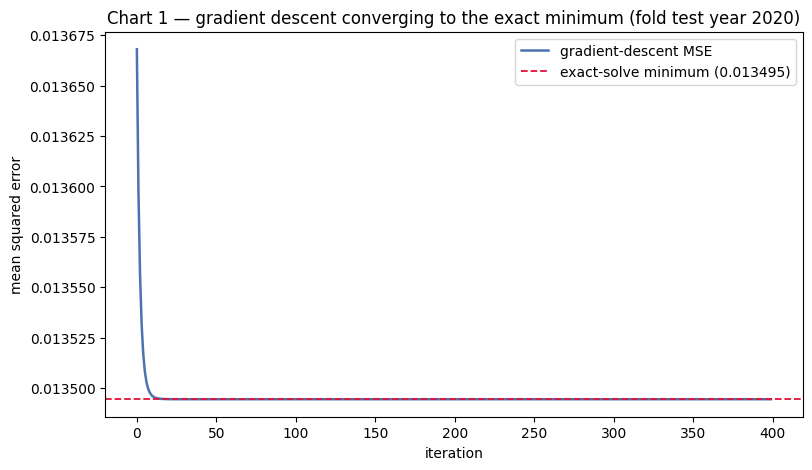

The curve falls fast then flattens onto the red line — that flattening IS convergence. This is what 'training' looks like for every model, nets included.


In [9]:
# CHART 1 — gradient-descent convergence: error falls to the exact-solve minimum
exact_err = np.mean((X @ w_exact - y)**2)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(err_hist, color="#4C72B0", lw=1.8, label="gradient-descent MSE")
ax.axhline(exact_err, color="crimson", ls="--", lw=1.3,
           label=f"exact-solve minimum ({exact_err:.6f})")
ax.set_xlabel("iteration"); ax.set_ylabel("mean squared error")
ax.set_title(f"Chart 1 — gradient descent converging to the exact minimum "
             f"(fold test year {rep['y0']+3})")
ax.legend()
save_fig(fig, "gd_convergence"); plt.show()
print("The curve falls fast then flattens onto the red line — that flattening IS "
      "convergence. This is what 'training' looks like for every model, nets included.")

  [saved: 02_gd_weight_migration.png]


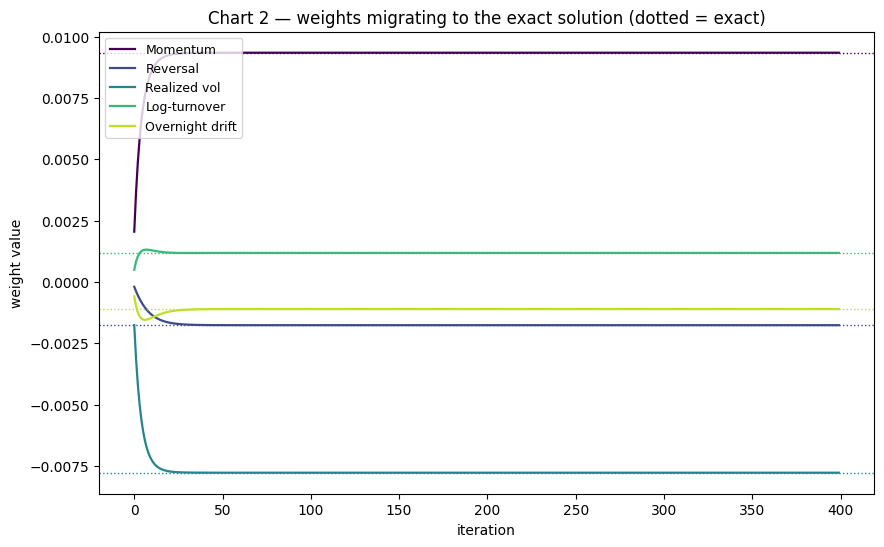

Each solid line (gradient descent) crawls to its dotted line (the exact answer). Seeing them meet is why we trust gradient descent on models with no formula.


In [10]:
# CHART 2 — the five weights migrating to their exact values during descent
colors = plt.cm.viridis(np.linspace(0, 0.9, 5))
fig, ax = plt.subplots(figsize=(10, 6))
for k, r in enumerate(RAW):
    ax.plot(w_hist[:, k+1], color=colors[k], lw=1.6, label=NICE[r])
    ax.axhline(w_exact[k+1], color=colors[k], ls=":", lw=1)
ax.set_xlabel("iteration"); ax.set_ylabel("weight value")
ax.set_title("Chart 2 — weights migrating to the exact solution (dotted = exact)")
ax.legend(fontsize=9)
save_fig(fig, "gd_weight_migration"); plt.show()
print("Each solid line (gradient descent) crawls to its dotted line (the exact "
      "answer). Seeing them meet is why we trust gradient descent on models with "
      "no formula.")

## Cell 4 — Score every fold: R2, Pearson IC, rank IC

**R2** — fraction of test-target variance the model explains. Out-of-sample R2
*can be negative* (worse than predicting the mean); we report it honestly.

**IC (Information Coefficient)** — the real cross-sectional scorecard. For each
test *day*, correlate predicted vs actual returns across that day's stocks. We
compute both **Pearson** (linear) and **rank/Spearman** (robust to the fat tails
we saw). Per fold: mean daily IC and % of days positive. A gap between rank and
Pearson IC is the fat tails talking.

In [11]:
from scipy.stats import spearmanr

def score_fold(coef, test):
    X = add_intercept(test[Z].to_numpy())
    pred = X @ coef
    actual = test[TARGET].to_numpy()
    ss_res = np.sum((actual - pred)**2)
    ss_tot = np.sum((actual - actual.mean())**2)
    r2 = 1 - ss_res/ss_tot
    tmp = test[["date"]].copy()
    tmp["pred"] = pred; tmp["actual"] = actual
    pear, rank = [], []
    for _, day in tmp.groupby("date"):
        if len(day) >= 30:
            pear.append(np.corrcoef(day["pred"], day["actual"])[0, 1])
            rank.append(spearmanr(day["pred"], day["actual"]).correlation)
    pear, rank = np.array(pear), np.array(rank)
    return dict(r2=r2, ic_pearson=np.nanmean(pear), ic_rank=np.nanmean(rank),
                pct_pos=np.mean(rank > 0), daily_rank_ic=rank,
                test_dates=sorted(tmp["date"].unique()))

scores = []
for f, coef in zip(folds, fold_weights):
    _, _, te = make_fold(f)
    s = score_fold(coef, te); s["test_year"] = f["y0"]+3
    scores.append(s)

stab = pd.DataFrame([{k: s[k] for k in ["test_year","r2","ic_pearson","ic_rank","pct_pos"]}
                     for s in scores])
print("Per-fold out-of-sample scores:")
print(stab.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print(f"\nPooled means: R2 {stab.r2.mean():+.4f} | "
      f"Pearson IC {stab.ic_pearson.mean():+.4f} | "
      f"rank IC {stab.ic_rank.mean():+.4f} | "
      f"days positive {stab.pct_pos.mean()*100:.0f}%")

Per-fold out-of-sample scores:
 test_year      r2  ic_pearson  ic_rank  pct_pos
      2014 -0.1107     +0.0871  +0.0930  +0.7172
      2015 -0.0305     +0.0631  +0.0791  +0.7702
      2016 -0.0029     +0.0197  +0.0141  +0.5425
      2017 -0.0142     +0.0433  +0.0513  +0.6653
      2018 -0.0846     +0.0736  +0.0890  +0.7154
      2019 +0.0091     +0.1687  +0.1460  +0.7224
      2020 -0.0249     +0.0264  +0.0291  +0.5339
      2021 -0.0776     +0.0153  +0.0421  +0.5887
      2022 -0.0311     +0.0167  +0.0252  +0.6492
      2023 -0.0113     +0.0258  +0.0189  +0.6612
      2024 -0.0086     +0.0094  -0.0018  +0.5285
      2025 -0.1185     +0.0474  +0.0623  +0.7366

Pooled means: R2 -0.0421 | Pearson IC +0.0497 | rank IC +0.0540 | days positive 65%


## Cell 5 — The remaining four charts

  [saved: 03_pred_vs_actual.png]


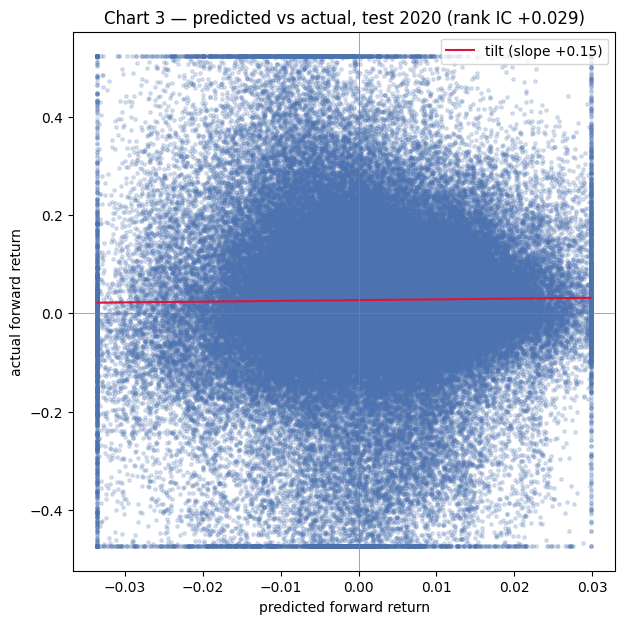

Almost a formless blob — but the red tilt is slightly positive. THAT faint tilt is what a small positive IC looks like. This is why we need the IC number: real cross-sectional signal is nearly invisible to the eye.


In [12]:
# CHART 3 — predicted vs actual on the representative test fold.
s_rep = score_fold(fold_weights[rep_idx], te_rep)
Xr = add_intercept(te_rep[Z].to_numpy())
pred_r = Xr @ fold_weights[rep_idx]
act_r = te_rep[TARGET].to_numpy()

fig, ax = plt.subplots(figsize=(7, 7))
lo_p, hi_p = np.percentile(pred_r, [1, 99]); lo_a, hi_a = np.percentile(act_r, [1, 99])
ax.scatter(np.clip(pred_r, lo_p, hi_p), np.clip(act_r, lo_a, hi_a),
           s=6, alpha=0.2, color="#4C72B0")
b1, b0 = np.polyfit(pred_r, act_r, 1)
xs = np.linspace(lo_p, hi_p, 50)
ax.plot(xs, b0 + b1*xs, color="crimson", lw=1.5, label=f"tilt (slope {b1:+.2f})")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("predicted forward return"); ax.set_ylabel("actual forward return")
ax.set_title(f"Chart 3 — predicted vs actual, test {rep['y0']+3} "
             f"(rank IC {s_rep['ic_rank']:+.3f})")
ax.legend()
save_fig(fig, "pred_vs_actual"); plt.show()
print("Almost a formless blob — but the red tilt is slightly positive. THAT faint "
      "tilt is what a small positive IC looks like. This is why we need the IC "
      "number: real cross-sectional signal is nearly invisible to the eye.")

  [saved: 04_weights_across_folds.png]


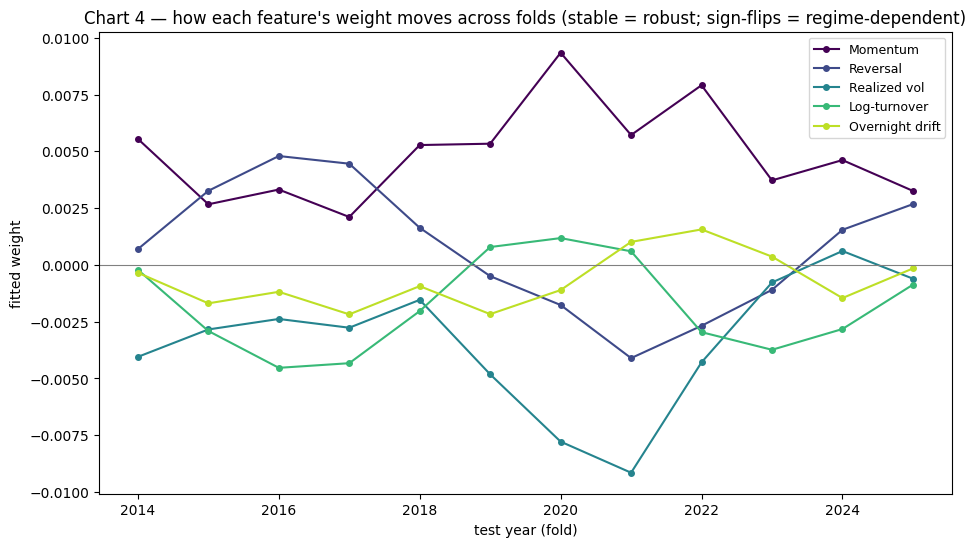

A weight that stays one side of zero is a robust relationship. One that flips sign between folds is a feature whose predictive direction is not stable across regimes — a genuine and important finding.


In [13]:
# CHART 4 — weights across folds (the non-stationarity window)
fig, ax = plt.subplots(figsize=(11, 6))
years = [f["y0"]+3 for f in folds]
for k, r in enumerate(RAW):
    ax.plot(years, [w[k+1] for w in fold_weights], marker="o", ms=4,
            color=colors[k], label=NICE[r])
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("test year (fold)"); ax.set_ylabel("fitted weight")
ax.set_title("Chart 4 — how each feature's weight moves across folds "
             "(stable = robust; sign-flips = regime-dependent)")
ax.legend(fontsize=9)
save_fig(fig, "weights_across_folds"); plt.show()
print("A weight that stays one side of zero is a robust relationship. One that "
      "flips sign between folds is a feature whose predictive direction is not "
      "stable across regimes — a genuine and important finding.")

  [saved: 05_ic_over_time.png]


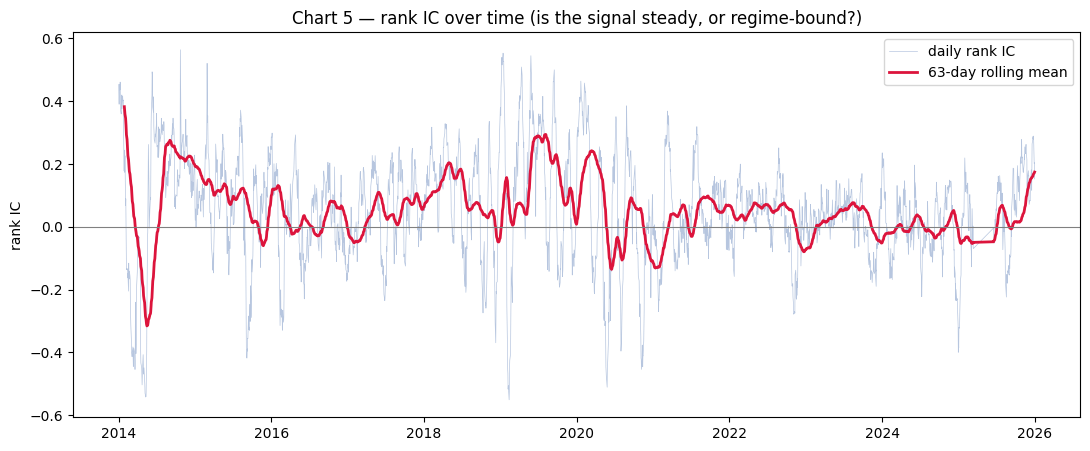

Watch whether the red line stays above zero or drifts through it. Signal that lives only in some years is invisible in the pooled average but obvious here.


In [14]:
# CHART 5 — rank IC over time (all folds' daily ICs concatenated), + rolling mean
fig, ax = plt.subplots(figsize=(13, 5))
all_dates_ic, all_ic = [], []
for s in scores:
    all_dates_ic.extend(s["test_dates"]); all_ic.extend(s["daily_rank_ic"])
order = np.argsort(all_dates_ic)
d = np.array(all_dates_ic)[order]; v = np.array(all_ic)[order]
ax.plot(d, v, lw=0.5, alpha=0.4, color="#4C72B0", label="daily rank IC")
roll = pd.Series(v).rolling(63, min_periods=20).mean()
ax.plot(d, roll, lw=2, color="crimson", label="63-day rolling mean")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("rank IC")
ax.set_title("Chart 5 — rank IC over time (is the signal steady, or regime-bound?)")
ax.legend()
save_fig(fig, "ic_over_time"); plt.show()
print("Watch whether the red line stays above zero or drifts through it. Signal "
      "that lives only in some years is invisible in the pooled average but obvious here.")

  [saved: 06_residual_vs_momentum.png]


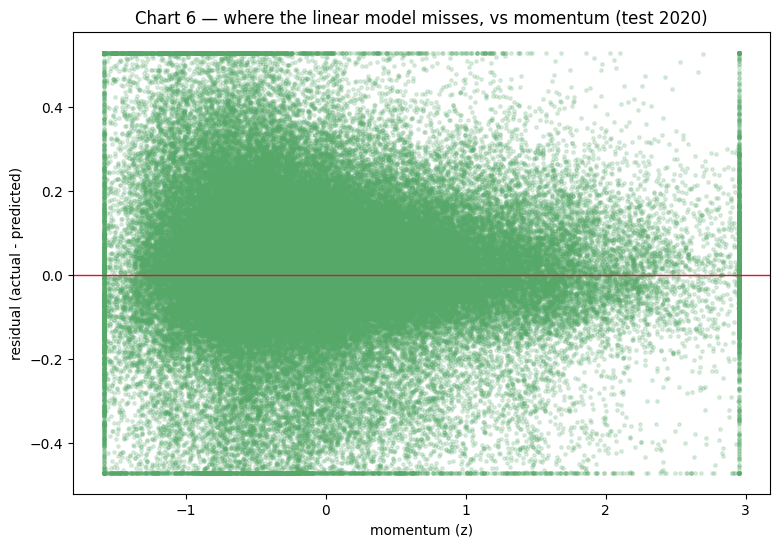

If residuals fan out or curve at extreme momentum, a straight line can't capture what happens in the tails — the concrete motivation for a nonlinear model (eventually a neural net) later.


In [15]:
# CHART 6 — residual vs momentum: WHERE does the linear model fail?
resid = act_r - pred_r
mom = te_rep["momentum_12_1_z"].to_numpy()
fig, ax = plt.subplots(figsize=(9, 6))
mlo, mhi = np.percentile(mom, [1, 99]); rlo, rhi = np.percentile(resid, [1, 99])
ax.scatter(np.clip(mom, mlo, mhi), np.clip(resid, rlo, rhi),
           s=6, alpha=0.2, color="#55A868")
ax.axhline(0, color="crimson", lw=1)
ax.set_xlabel("momentum (z)"); ax.set_ylabel("residual (actual - predicted)")
ax.set_title(f"Chart 6 — where the linear model misses, vs momentum (test {rep['y0']+3})")
save_fig(fig, "residual_vs_momentum"); plt.show()
print("If residuals fan out or curve at extreme momentum, a straight line can't "
      "capture what happens in the tails — the concrete motivation for a nonlinear "
      "model (eventually a neural net) later.")

## Cell 6 — Copy-paste summary

In [16]:
print("="*70)
print("SAVED FIGURES:", EXPORT_DIR)
for p in sorted(EXPORT_DIR.glob("*.png")): print("   ", p.name)
print("="*70)
print("COPY BELOW THIS LINE AND PASTE BACK")
print("="*70)
print("\n[per-fold scores]")
print(stab.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print(f"\n[pooled] R2 {stab.r2.mean():+.4f} | Pearson IC {stab.ic_pearson.mean():+.4f} "
      f"| rank IC {stab.ic_rank.mean():+.4f} | days+ {stab.pct_pos.mean()*100:.0f}%")
print("\n[exact-solve weights per fold]")
print(wtab.to_string(index=False, float_format=lambda x: f"{x:+.5f}"))
print(f"\n[gradient descent, fold {rep['y0']+3}] max|GD - exact| = "
      f"{np.abs(w_gd-w_exact).max():.2e}, final MSE {err_hist[-1]:.6f} vs exact {exact_err:.6f}")
print("="*70)

SAVED FIGURES: /content/drive/MyDrive/moonshot_ml_sandbox/viz_exports_regression
    01_gd_convergence.png
    02_gd_weight_migration.png
    03_pred_vs_actual.png
    04_weights_across_folds.png
    05_ic_over_time.png
    06_residual_vs_momentum.png
COPY BELOW THIS LINE AND PASTE BACK

[per-fold scores]
 test_year      r2  ic_pearson  ic_rank  pct_pos
      2014 -0.1107     +0.0871  +0.0930  +0.7172
      2015 -0.0305     +0.0631  +0.0791  +0.7702
      2016 -0.0029     +0.0197  +0.0141  +0.5425
      2017 -0.0142     +0.0433  +0.0513  +0.6653
      2018 -0.0846     +0.0736  +0.0890  +0.7154
      2019 +0.0091     +0.1687  +0.1460  +0.7224
      2020 -0.0249     +0.0264  +0.0291  +0.5339
      2021 -0.0776     +0.0153  +0.0421  +0.5887
      2022 -0.0311     +0.0167  +0.0252  +0.6492
      2023 -0.0113     +0.0258  +0.0189  +0.6612
      2024 -0.0086     +0.0094  -0.0018  +0.5285
      2025 -0.1185     +0.0474  +0.0623  +0.7366

[pooled] R2 -0.0421 | Pearson IC +0.0497 | rank IC +0.0

## What this teaches, and where it points

- **R2 vs IC**: you'll likely see a tiny (or negative) R2 sitting next to a small
  positive IC — the lesson that *ranking* is an easier, more useful task than
  *exact prediction* for cross-sectional equity.
- **Weights across folds (Chart 4)**: which features carry stable predictive
  direction and which flip — your first read of feature robustness over regimes.
- **IC over time (Chart 5)**: whether the signal is steady or regime-bound.
- **Residual vs momentum (Chart 6)**: where a straight line fails — the concrete
  motivation for nonlinearity next.

**Not done here (deliberately):** regularization, interactions/polynomial terms,
target residualization (dataset V2/V3). Each is a modification to try *after* the
plain version is understood.